<a href="https://colab.research.google.com/github/Bhushan1024/Bhushan1024/blob/main/Sleep_ScreenTime_Simulation_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Removed: 9 | Kept: 291
           count  mean   std
sleep_grp                   
<7h          216  6.58  0.76
>=7h          75  6.99  0.73
            count  mean   std
screen_grp                   
Low            52  7.09  0.71
Moderate      141  6.79  0.68
High           98  6.32  0.79
         cgpa   sleep  screen
count  291.00  291.00  291.00
mean     6.68    6.30    3.62
std      0.77    1.03    1.75
min      4.56    3.50    0.40
25%      6.18    5.60    2.30
50%      6.69    6.30    3.40
75%      7.18    7.00    4.60
max      9.28    9.30    9.70
TtestResult(statistic=np.float64(4.1803157992336955), pvalue=np.float64(5.203852498774355e-05), df=np.float64(134.9292409940889))
Bootstrap 95% CI: [0.226 0.608]
F_onewayResult(statistic=np.float64(21.866210488666844), pvalue=np.float64(1.4423080143323065e-09))
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1  group2  meandiff p-adj   lower   upper  reject
------------------------------------------------------
  High      Lo

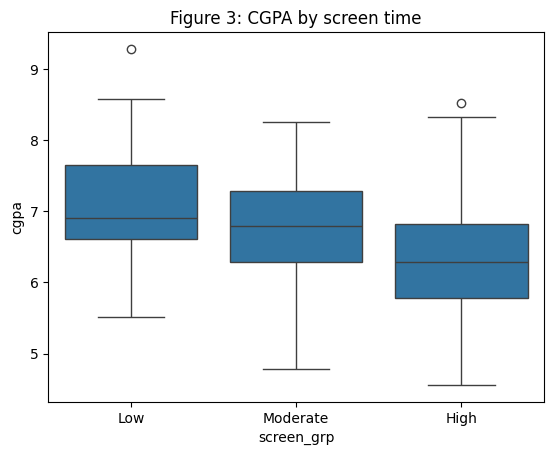

In [2]:
import pandas as pd, numpy as np
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("survey.csv")   # columns: cgpa, sleep, screen, residence, year

# 1. Cleaning
before = len(df)
df = df.dropna(subset=["cgpa", "sleep", "screen"])
df = df[df.cgpa.between(0, 10) & df.sleep.between(2, 14) & df.screen.between(0, 16)]
print("Removed:", before - len(df), "| Kept:", len(df))

# 2. Groups
df["sleep_grp"] = np.where(df.sleep >= 7, ">=7h", "<7h")
df["screen_grp"] = pd.cut(df.screen, [-1, 2, 4, 24], labels=["Low", "Moderate", "High"])
print(df.groupby("sleep_grp").cgpa.agg(["count", "mean", "std"]).round(2))
print(df.groupby("screen_grp", observed=True).cgpa.agg(["count", "mean", "std"]).round(2))

# 3. Descriptive statistics (Table 5.2)
print(df[["cgpa", "sleep", "screen"]].describe().round(2))

# 4. H1: Welch t-test + bootstrap CI
a = df[df.sleep_grp == ">=7h"].cgpa
b = df[df.sleep_grp == "<7h"].cgpa
print(stats.ttest_ind(a, b, equal_var=False))
boot = [np.random.choice(a, len(a)).mean() - np.random.choice(b, len(b)).mean() for _ in range(5000)]
print("Bootstrap 95% CI:", np.percentile(boot, [2.5, 97.5]).round(3))

# 5. H2: one-way ANOVA + Tukey
groups = [g.cgpa for _, g in df.groupby("screen_grp", observed=True)]
print(stats.f_oneway(*groups))
from statsmodels.stats.multicomp import pairwise_tukeyhsd
print(pairwise_tukeyhsd(df.cgpa, df.screen_grp.astype(str)))

# 6. H3: chi-square
table = pd.crosstab(df.sleep_grp, df.screen_grp)
chi2, p, dof, _ = stats.chi2_contingency(table)
print(table, "\nchi2 =", round(chi2, 3), "p =", round(p, 4), "df =", dof)

# 7. H4: multiple regression
model = smf.ols("cgpa ~ sleep + screen", data=df).fit()
print(model.summary())

# 8. Figures
sns.histplot(df.sleep, bins=10); plt.title("Figure 1: Sleep hours"); plt.savefig("fig1.png"); plt.clf()
sns.regplot(x="sleep", y="cgpa", data=df); plt.title("Figure 2: Sleep vs CGPA"); plt.savefig("fig2.png"); plt.clf()
sns.boxplot(x="screen_grp", y="cgpa", data=df); plt.title("Figure 3: CGPA by screen time"); plt.savefig("fig3.png")